# Validação Cruzada no WineQT

A validação cruzada ajuda a verificar estabilidade do modelo e reduzir a dependência de uma divisão única em treino/teste.

Duas abordagens serão avaliadas:
- K-Fold Cross-Validation
- Leave-One-Out Cross-Validation (LOOCV)


KFold F1 scores: [np.float64(0.4717), np.float64(0.5098), np.float64(0.5417), np.float64(0.4954), np.float64(0.5319)]
KFold F1 média: 0.5101
KFold F1 desvio: 0.0252


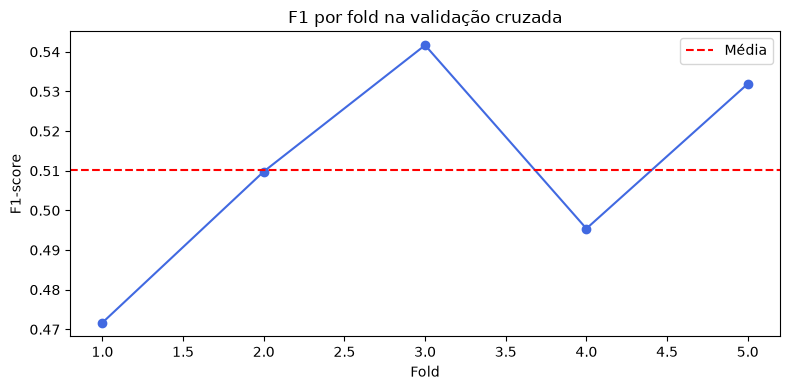

In [3]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

wine = pd.read_csv('../data/WineQT.csv')
wine['target'] = (wine['quality'] >= 7).astype(int)
X = wine[[c for c in wine.columns if c not in {'quality', 'target', 'Id'}]]
y = wine['target']

pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=4000, class_weight='balanced', random_state=42)
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, X, y, cv=cv, scoring='f1')

print('KFold F1 scores:', [round(v, 4) for v in cv_scores])
print('KFold F1 média:', round(cv_scores.mean(), 4))
print('KFold F1 desvio:', round(cv_scores.std(), 4))

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cv_scores) + 1), cv_scores, marker='o', color='royalblue')
plt.axhline(cv_scores.mean(), color='red', linestyle='--', label='Média')
plt.title('F1 por fold na validação cruzada')
plt.xlabel('Fold')
plt.ylabel('F1-score')
plt.legend()
plt.tight_layout()
plt.show()


In [4]:
loo = LeaveOneOut()
loo_scores = cross_val_score(pipe, X, y, cv=loo, scoring='f1')

print('LOOCV F1 média:', round(loo_scores.mean(), 4))
print('LOOCV F1 desvio:', round(loo_scores.std(), 4))
print('LOOCV F1 min/max:', round(loo_scores.min(), 4), round(loo_scores.max(), 4))


/home/paulo/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/paulo/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/paulo/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

LOOCV F1 média: 0.1111
LOOCV F1 desvio: 0.3143
LOOCV F1 min/max: 0.0 1.0


/home/paulo/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/paulo/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/paulo/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

# Interpretação
#
# A validação cruzada confirma se o modelo mantém desempenho quando o conjunto é percorrido em diferentes
# divisões. Se os valores forem estáveis e próximos da média, a evidência de generalização é mais forte.
#
# No caso do WineQT, o F1 em K-Fold e LOOCV atua como teste mais realista do que uma única divisão fixa.
